# Imports and Variables

In [ ]:
# Environment uses Python 3.10.17 and scikit-learn 1.6.1
import sys
from pathlib import Path

# Repo layout: run this notebook from notebooks/ (or from the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATASET_DIR = ROOT / "data" / "hyperview2"  # train/ and test/ folders, train_gt.csv
FIGURES_DIR = ROOT / "figures"
OUTPUTS_DIR = ROOT / "outputs"
OUTPUTS_DIR.mkdir(exist_ok=True)

from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, gaussian_kde
import seaborn as sns
import shap

from data_loading import load_data
from predict_pipeline import hype_spectral_wrapper

In [ ]:
np.random.seed(42)
column_names = ['Fe', 'Zn', 'B', 'Cu', 'S', 'Mn']
soil_properties = ['Iron', 'Zinc', 'Boron', 'Copper', 'Sulphur', 'Manganese']
n_targets = 6
wavelengths_hsi = pd.read_json(ROOT / "data" / "wavelengths.json").hsi_satellite_wavelengths.dropna()
wavelengths_msi = pd.read_json(ROOT / "data" / "wavelengths.json").msi_satellite_wavelengths.dropna()
sentinel2_bands = ['Aerosol', 'Blue', 'Green', 'Red', 'Red Edge 1', 'Red Edge 2', 'Red Edge 3', 'NIR (842nm)', 'Narrow NIR', 'NIR (945nm)', 'SWIR 1', 'SWIR 2']

**Short Summary of our approach**:

I treat each method as a pipeline, meaning that the unprocessed input data (i.e. MSI and HSI bands) are passed through a pipeline for each method. The pipeline includes any preprocessing steps and the model(s). This allows us to get SHAP values for the raw input directly and allows for a direct comparison between methods. If we compared the input to the models after any pre-processing, this would not be possible.

To obtain results for a different top-performing method, one has to write a wrapper function (this mostly requires copying the code from each inference notebook).

In [3]:
# Load the data
# Mean reflectance for the whole field
X_train_dict, X_test_dict, y_train, n_valid_pixels_train_dict, n_valid_pixels_test_dict = load_data(reductions=['mean'], DATASET_DIR=DATASET_DIR)

X_train_hsi = np.array(X_train_dict['hsi_satellite'])
X_train_msi = np.array(X_train_dict['msi_satellite'])
X_test_hsi = np.array(X_test_dict['hsi_satellite'])
X_test_msi = np.array(X_test_dict['msi_satellite'])

# 1 Modality and Spectral Band Importance
## 1.1 Spectral Band Importance

In [ ]:
# Combine MSI and HSI bands (mean reflectances per field) into one dataset
X_train_combined = np.hstack((X_train_msi, X_train_hsi))
X_test_combined = np.hstack((X_test_msi, X_test_hsi))

# Take a random subset of 1000 train and 200 test samples
X_train_subset = X_train_combined[np.random.choice(X_train_combined.shape[0], size=1000, replace=False), :]
test_subset_indices = np.random.choice(X_test_combined.shape[0], size=200, replace=False)
X_test_subset = X_test_combined[test_subset_indices, :]

In [ ]:
shap_values_targets = {}
explainers = {}
expected_values = {}

for i in range(n_targets):
    predict_pipeline = hype_spectral_wrapper(i)
    
    # Use PermutationExplainer to get feature importances
    # Partition masker for correlated features
    explainer = shap.Explainer(predict_pipeline, masker=shap.maskers.Partition(X_train_subset))
    shap_values_targets[i] = explainer(X_test_subset).values
    explainers[i] = explainer
    expected_values[i] = predict_pipeline(X_train_subset)

PermutationExplainer explainer: 201it [13:01,  3.93s/it]                         
PermutationExplainer explainer: 201it [13:01,  3.97s/it]                         
PermutationExplainer explainer: 201it [12:09,  3.70s/it]                         
PermutationExplainer explainer: 201it [12:45,  3.89s/it]                         
PermutationExplainer explainer: 201it [12:31,  3.81s/it]                         
PermutationExplainer explainer: 201it [12:27,  3.80s/it]                         


[3.14585632 5.48883692 3.29847922 3.36918567 5.23366626 7.38540913
 1.48731195 1.69801198 3.55513839 5.53408089 1.66190511 1.70055065]
[0.19508648 0.1462691  0.12384701 0.15772388 0.08604418 0.13829937
 0.05768699 0.07112438 0.04071064 0.1703845  0.09054881 0.14325789]
[0.01720871 0.01338227 0.01459537 0.02087153 0.00879872 0.0108756
 0.00790565 0.00459268 0.00371437 0.01504871 0.01002956 0.01432694]
[0.03506539 0.03165267 0.03788351 0.02702366 0.01587316 0.03425102
 0.01537763 0.01564663 0.0087252  0.03100779 0.03968164 0.02833547]
[0.58878317 0.84321746 0.4443419  0.39561588 0.6690014  0.49324934
 0.27619146 0.47462564 0.37029376 0.46044714 1.30873407 0.58565212]
[1.2196165  1.19405281 0.46643269 0.60049269 0.68939022 1.21786108
 0.74716423 1.27492666 0.53783114 1.18105182 1.10103408 0.73140856]


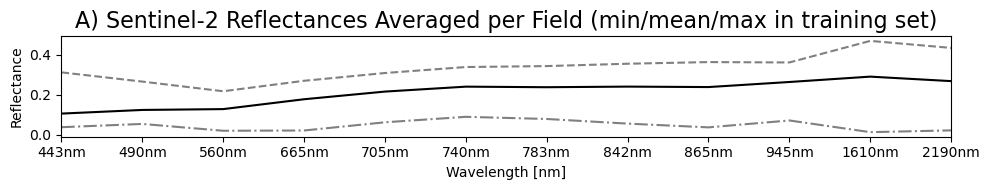

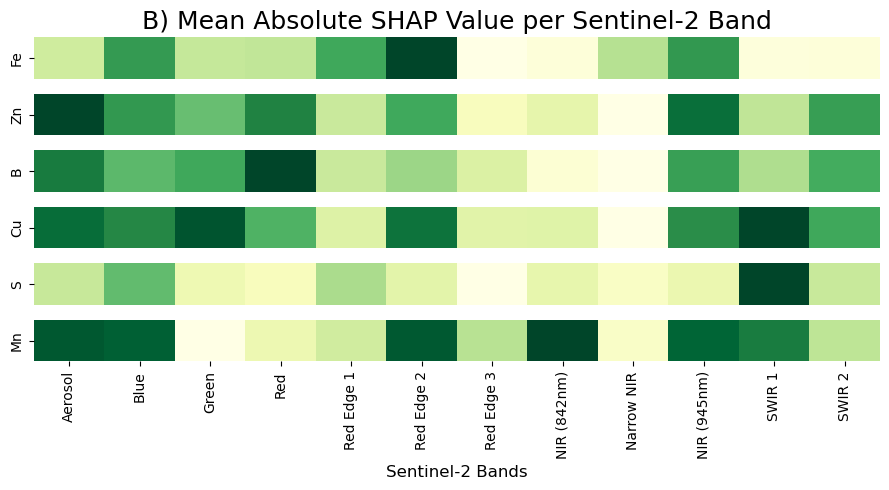

In [ ]:
fig, ax = plt.subplots(figsize=(10, 2))
plt.plot(np.mean(X_test_msi, axis=0), c='black')
plt.plot(np.nanmin(X_test_msi, axis=0), c='grey', linestyle='-.')
plt.plot(np.nanmax(X_test_msi, axis=0), c='grey', linestyle='--')
ax.set_title("A) Sentinel-2 Reflectances Averaged per Field (min/mean/max in training set)", fontsize=16)
ax.set_xticks(range(len(wavelengths_msi)))
ax.set_xticklabels(str(int(round(number)))+'nm' for number in wavelengths_msi)

# Set the x axis limit to match the data range without whitespace
ax.set_xlim([0, len(wavelengths_msi) - 1])

plt.ylabel("Reflectance")
plt.xlabel("Wavelength [nm]")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "xai_sentinel2_reflectance.png", dpi=300)

# Create a figure and 6 subplots (6 rows, 1 column)
fig, axs = plt.subplots(6, 1, figsize=(9, 5))

# Iterate through each subplot
for i, ax in enumerate(axs):
    shap_values_msi = shap_values_targets[i][:, :X_test_msi.shape[1]]  # first 12 SHAP values are for Sentinel-2
    # Mean across the SHAP values from the 200 test samples to get one value per band
    mean_abs_shap_msi = np.mean(np.abs(shap_values_msi), axis=0)
    print(mean_abs_shap_msi)

    sns.heatmap(
        np.expand_dims(mean_abs_shap_msi, axis=0),
        yticklabels=[column_names[i]],
        xticklabels=sentinel2_bands if i == len(axs) - 1 else False,
        ax=ax,
        cmap="YlGn",
        cbar=False
    )
ax.set_xlabel("Sentinel-2 Bands", fontsize=12)
axs[0].set_title("B) Mean Absolute SHAP Value per Sentinel-2 Band", fontsize=18)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "xai_sentinel2_band_importance.png", dpi=300)

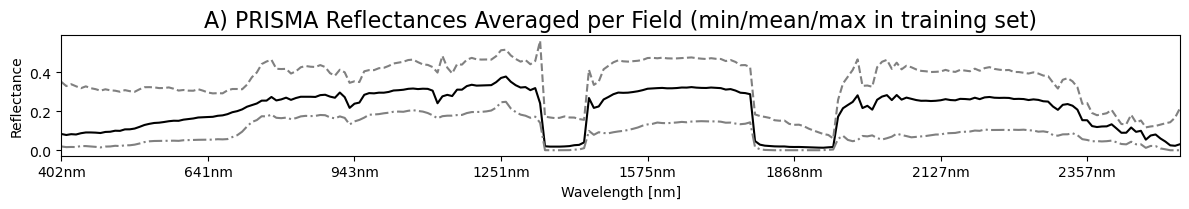

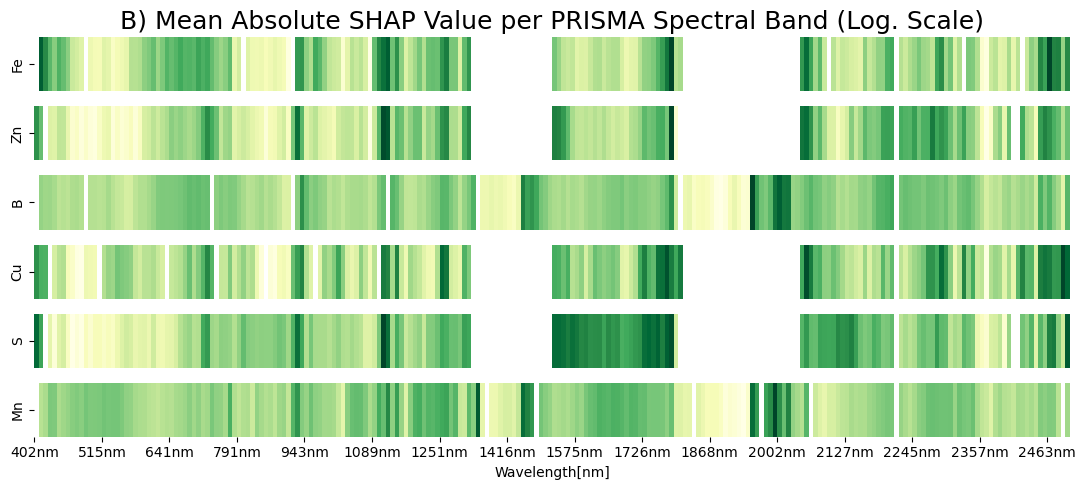

In [ ]:
# We mask out the bands at the following indices, because they were added as additional features
# to the models, hence they have very high SHAP values and dominate the resulting plot if not removed.
# (different bands were added for each soil property)
raw_hsi_bands_indices_dict = {
    "top_features_0": [191, 176, 219, 206, 46, 57, 0, 11],
    "top_features_1": [191, 2, 218, 143, 217, 161, 150],
    "top_features_2": [191, 0, 11, 98, 39, 78, 57, 143],
    "top_features_3": [191, 62, 76, 3, 14, 29, 40, 51],
    "top_features_4": [191, 2, 218, 143, 217, 161, 150],
    "top_features_5": [191, 0, 100, 111, 146, 161, 172, 228],
}

fig, ax = plt.subplots(figsize=(12, 2.2))
plt.plot(np.mean(X_test_hsi, axis=0), c='black')
plt.plot(np.nanmin(X_test_hsi, axis=0), c='grey', linestyle='-.')
plt.plot(np.nanmax(X_test_hsi, axis=0), c='grey', linestyle='--')
# Set an xtick and label every 30th band
ax.set_xticks(range(0, len(wavelengths_hsi), 30))
ax.set_xticklabels(str(int(round(number)))+'nm' for number in wavelengths_hsi[::30])

# Set the x axis limit to match the data range without whitespace
ax.set_xlim([0, len(wavelengths_hsi) - 1])

plt.xlabel("Wavelength [nm]")
plt.ylabel("Reflectance")
ax.set_title("A) PRISMA Reflectances Averaged per Field (min/mean/max in training set)", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "xai_prisma_reflectance.png", dpi=300)

# Create a figure with 6 subplots (6 rows, 1 column)
fig, axs = plt.subplots(6, 1, figsize=(11, 5))

for i, ax in enumerate(axs):
    shap_values_hsi = shap_values_targets[i][:, 12:] # first 12 are Sentinel 2
    mean_abs_shap_hsi = np.mean(np.abs(shap_values_hsi), axis=0)
    added_bands = raw_hsi_bands_indices_dict["top_features_"+str(i)]
    mean_abs_shap_hsi[added_bands] = np.nan

    log_norm = LogNorm()    
    sns.heatmap(
        np.expand_dims(mean_abs_shap_hsi, axis=0),
        yticklabels=[column_names[i]],
        xticklabels=False,
        ax=ax,
        cmap="YlGn",
        cbar=False,
        norm=log_norm
    )
ax.set_xticks(range(0, len(wavelengths_hsi), 15))
ax.set_xticklabels(str(int(round(number)))+'nm' for number in wavelengths_hsi[::15])
ax.set_xlabel("Wavelength[nm]")
axs[0].set_title("B) Mean Absolute SHAP Value per PRISMA Spectral Band (Log. Scale)", fontsize=18)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "xai_prisma_band_importance.png", dpi=300)

## 1.2 Modality Importance

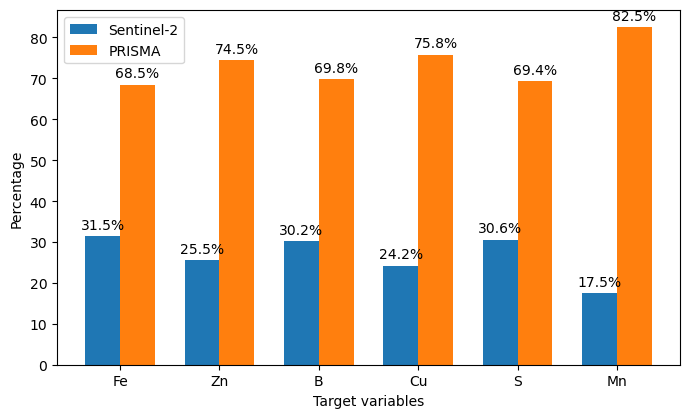

In [ ]:
n_targets = len(column_names)
msi_percentages = []
hsi_percentages = []

for i in range(n_targets):
    shap_values_var = shap_values_targets[i]

    # Separate SHAP values for MSI and HSI modalities
    shap_values_msi = shap_values_var[:, :12]
    abs_sum_shap_values_msi = np.sum(np.abs(shap_values_msi))

    shap_values_hsi = shap_values_var[:, 12:]
    abs_sum_shap_values_hsi = np.sum(np.abs(shap_values_hsi))

    # Calculate percentages
    total_sum_shap_values = abs_sum_shap_values_msi + abs_sum_shap_values_hsi
    msi_percentage = round(abs_sum_shap_values_msi / total_sum_shap_values * 100, 1)
    hsi_percentage = round(abs_sum_shap_values_hsi / total_sum_shap_values * 100, 1)

    # Append to lists for plotting
    msi_percentages.append(msi_percentage)
    hsi_percentages.append(hsi_percentage)

# Plotting the percentages as a grouped bar chart
x = np.arange(n_targets)  # the label locations
width = 0.35  # width of the bars

fig, ax = plt.subplots(figsize=(7, 4.3))

bars1 = ax.bar(x - width/2, msi_percentages, width, label='Sentinel-2')
bars2 = ax.bar(x + width/2, hsi_percentages, width, label='PRISMA')

ax.set_xlabel('Target variables')
ax.set_ylabel('Percentage')
ax.set_xticks(x)
ax.set_xticklabels(column_names)
ax.legend()

# Add percentage values on top of bars
def add_perc_values_to_bars(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

add_perc_values_to_bars(bars1)
add_perc_values_to_bars(bars2)

fig.tight_layout()
plt.savefig(FIGURES_DIR / "xai_modality_share.png", dpi=300)

# 2 Susceptibility to Noise / Low Quality Data

In [ ]:
# Define three noise levels with different sigma values for the additive gaussian noise
noise_levels = {'small': 0.005, 'medium': 0.01, 'high': 0.03}
def add_noise(x, sigma):
    """Additive gaussian noise. Sigma is the standard deviation of the noise."""
    return x + np.random.normal(0, sigma, x.shape)

In [ ]:
# Create noisy versions of X_test_hsi and X_test_msi for each noise level
X_test_noisy = {}
for noise_name, sigma in noise_levels.items():
    X_test_hsi_noisy = np.array([add_noise(x, sigma=sigma) for x in X_test_hsi])
    X_test_msi_noisy = np.array([add_noise(x, sigma=sigma) for x in X_test_msi])
    
    # Combine raw MSI and HSI features into one dataset
    X_test_combined_noisy = np.hstack((X_test_msi_noisy, X_test_hsi_noisy))
    X_test_combined_noisy[X_test_combined_noisy < 0] = 0
    
    # Select the same subset of 200 samples for SHAP analysis
    X_test_subset_noisy = X_test_combined_noisy[test_subset_indices, :]
    
    X_test_noisy[noise_name] = X_test_subset_noisy

In [ ]:
shap_values_noise_targets = {}
y_pred_no_noise = {}
y_pred_noise = {}

for i in range(n_targets):
    predict_pipeline = hype_spectral_wrapper(i)  # get the prediction pipeline
    explainer = explainers[i]  # get the SHAP explainer
    
    shap_values_noise_targets[i] = {}
    y_pred_noise[i] = {}
    
    for noise_name, X_test_subset_noisy in X_test_noisy.items():
        shap_values = explainer(X_test_subset_noisy).values
        shap_values_noise_targets[i][noise_name] = shap_values
        expected_value = np.mean(expected_values[i])
        
        # Calculate predictions from SHAP values with noise
        y_pred_from_shap_noisy = expected_value + np.sum(shap_values, axis=1)
        y_pred_noise[i][noise_name] = y_pred_from_shap_noisy

    # Calculate predictions from SHAP values without noise
    f_pred_from_shap = expected_value + np.sum(shap_values_targets[i], axis=1)
    y_pred_no_noise[i] = f_pred_from_shap

PermutationExplainer explainer: 201it [11:41,  3.56s/it]                         
PermutationExplainer explainer: 201it [11:33,  3.52s/it]                         
PermutationExplainer explainer: 201it [11:27,  3.49s/it]                         
PermutationExplainer explainer: 201it [12:31,  3.82s/it]                         
PermutationExplainer explainer: 201it [12:26,  3.79s/it]                         
PermutationExplainer explainer: 201it [12:24,  3.78s/it]                         
PermutationExplainer explainer: 201it [12:27,  3.80s/it]                         
PermutationExplainer explainer: 201it [12:24,  3.78s/it]                         
PermutationExplainer explainer: 201it [12:12,  3.72s/it]                         
PermutationExplainer explainer: 201it [11:58,  3.65s/it]                         
PermutationExplainer explainer: 201it [12:03,  3.67s/it]                         
PermutationExplainer explainer: 201it [12:03,  3.67s/it]                         


In [ ]:
colors = {'small': 'gold', 'medium': 'darkorange', 'high': 'red'}
noise_names = {'small': 'low', 'medium': 'medium', 'high': 'high'}

def calculate_prediction_drift(y_pred_no_noise, y_pred_noise):
    # MAD = Mean Absolute Difference
    mad = np.mean(np.abs(y_pred_no_noise - y_pred_noise))
    return mad

def calculate_explanation_drift(shap_values_targets, shap_values_noise_targets):
    correlation_coefficient, _ = pearsonr(shap_values_targets.flatten(), shap_values_noise_targets.flatten())
    mac = np.mean(np.abs(shap_values_targets - shap_values_noise_targets))
    relative_mac = ((mac - np.mean(np.abs(shap_values_targets))) / np.mean(np.abs(shap_values_targets))) * 100
    return correlation_coefficient, relative_mac

def create_results_table(n_targets, y_pred_no_noise, y_pred_noise, shap_values_targets, shap_values_noise_targets):
    results = []
    for i in range(n_targets):
        for noise_name, y_pred_noise_i in y_pred_noise[i].items():
            correlation_coefficient, relative_mac = calculate_explanation_drift(shap_values_targets[i], shap_values_noise_targets[i][noise_name])
            results.append({
                'Target': i,
                'Noise Level': noise_name,
                'Correlation Coefficient': round(correlation_coefficient, 2),
                'Relative MAC (%)': round(relative_mac, 1)
            })
    df = pd.DataFrame(results)
    return df

n_targets = len(y_pred_no_noise)

# Create figure with 3 columns and 2 rows for the six target variables
fig, axs = plt.subplots(2, 3, figsize=(12, 6))

for i in range(n_targets):
    row = i // 3
    col = i % 3
    
    mad_values = {}
    
    # Plot the distribution with noisy inputs
    for noise_name, y_pred_noise_i in y_pred_noise[i].items():
        # Plot the gaussian kernel density estimate
        kde_noise = gaussian_kde(y_pred_noise_i)
        x = np.linspace(np.min(y_pred_no_noise[i]), np.max(y_pred_no_noise[i]), 1000)
        line, = axs[row, col].plot(x, kde_noise(x), label=noise_names[noise_name], linestyle='--', color=colors[noise_name])
        
        mad = calculate_prediction_drift(y_pred_no_noise[i], y_pred_noise_i)
        mad_values[noise_name] = mad
    
    # Plot no noise distribution
    kde_no_noise = gaussian_kde(y_pred_no_noise[i])
    x = np.linspace(np.min(y_pred_no_noise[i]), np.max(y_pred_no_noise[i]), 1000)
    line, = axs[row, col].plot(x, kde_no_noise(x), label='No Noise', color='black')
    
    axs[row, col].set_title(f"{soil_properties[i]}")
    axs[row, col].set_xlabel('Prediction Values')
    axs[row, col].set_ylabel('Density')
    axs[row, col].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "xai_noise_density.png")
plt.close()

# Create results table
df = create_results_table(n_targets, y_pred_no_noise, y_pred_noise, shap_values_targets, shap_values_noise_targets)

# Create LaTeX table
pivot_df = df.pivot(index='Target', columns=['Noise Level'], values=['Correlation Coefficient', 'Relative MAC (%)'])
reordered_pivot_df = pivot_df.reindex(noise_levels, axis=1, level=1)
latex_table = reordered_pivot_df.to_latex(float_format="{:.2f}".format)
print(latex_table)

# Save results
df.to_csv(OUTPUTS_DIR / 'xai_noise_results.csv', index=False)
print("Results table saved to outputs/xai_noise_results.csv")

\begin{tabular}{lrrrrrr}
\toprule
 & \multicolumn{3}{r}{Correlation Coefficient} & \multicolumn{3}{r}{Relative MAC (%)} \\
Noise Level & small & medium & high & small & medium & high \\
Target &  &  &  &  &  &  \\
\midrule
0 & 0.68 & 0.62 & 0.45 & -3.40 & 4.50 & 22.80 \\
1 & 0.63 & 0.56 & 0.39 & -3.10 & 5.50 & 27.00 \\
2 & 0.69 & 0.63 & 0.46 & -13.30 & -6.90 & 13.80 \\
3 & 0.57 & 0.50 & 0.36 & -2.30 & 5.70 & 27.40 \\
4 & 0.76 & 0.72 & 0.55 & -14.70 & -8.50 & 14.00 \\
5 & 0.78 & 0.73 & 0.54 & -19.30 & -11.00 & 19.10 \\
\bottomrule
\end{tabular}

Results table saved to results_table.csv


In [ ]:
# Aggregate the correlation coefficient across targets (soil properties) and noise levels
correlation_pivot_df = df.pivot(index='Target', columns='Noise Level', values='Correlation Coefficient')

# Reorder columns
noise_levels = ['small', 'medium', 'high']
correlation_pivot_df = correlation_pivot_df.reindex(noise_levels, axis=1)

# Create heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(correlation_pivot_df, annot=True, cmap='coolwarm', fmt='.2f',
            vmin=-1, vmax=1)
plt.xlabel('Noise Level')
column_names = ['Fe', 'Zn', 'B', 'Cu', 'S', 'Mn']
plt.yticks(np.arange(len(column_names)) + 0.5, column_names)
noise_level_labels = ['Low', 'Medium', 'High']
plt.xticks(np.arange(len(noise_level_labels)) + 0.5, noise_level_labels)
plt.ylabel('Soil Property')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "xai_noise_correlation_heatmap.png")
plt.close()